In [3]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score,classification_report

In [4]:
iris=load_iris()
X=iris.data
y=iris.target
print("Feature names:")
print(iris.feature_names)
print("\nTarget names:")
print(iris.target_names)
print("\nShape of datasets:",X.shape)

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target names:
['setosa' 'versicolor' 'virginica']

Shape of datasets: (150, 4)


In [5]:
y_binary=(y!=0).astype(int)
print("Binary labes")
print(np.unique(y_binary,return_counts=True))

X_two=X[:,[2,3]]

Binary labes
(array([0, 1]), array([ 50, 100]))


In [6]:
X_train,X_test,y_train,y_test=train_test_split(
X_two,
y_binary,
test_size=0.2,
random_state=42,
stratify=y_binary
)

In [12]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

linear_svm=SVC(
    kernel='linear',
    C=1.0
)
linear_svm.fit(X_train_scaled,y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [13]:
y_pred=linear_svm.predict(X_test_scaled)
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)
print("\nClassification Report:")
print(classification_report(y_test,y_pred))

Accuracy: 1.0

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      1.00      1.00        20

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



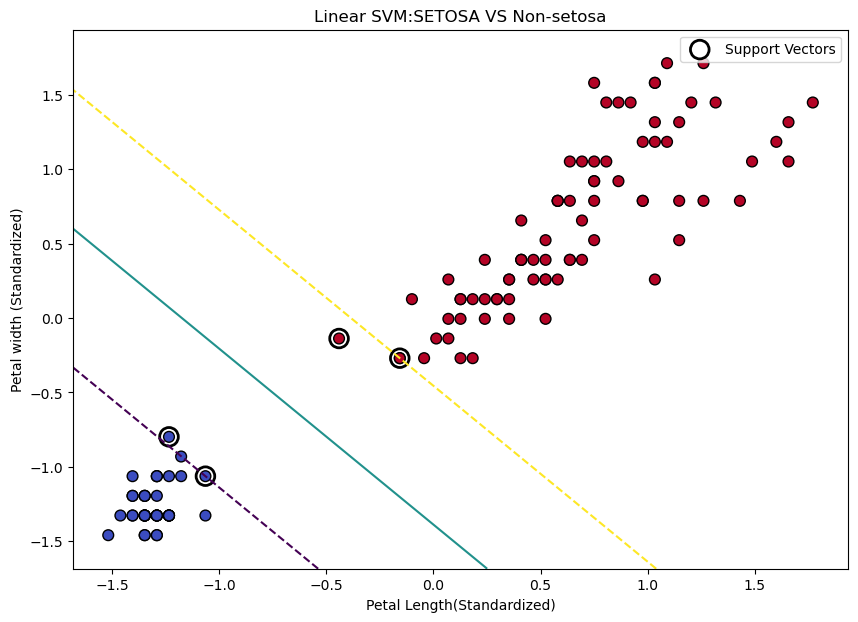

In [32]:
plt.figure(figsize=(10,7))
plt.scatter(
    X_train_scaled[:,0],
    X_train_scaled[:,1],
    c=y_train,
    s=60,
    cmap='coolwarm',
    edgecolors='k'
)



ax=plt.gca()
xlim=ax.get_xlim()
ylim=ax.get_xlim()
xx=np.linspace(xlim[0],xlim[1],200)
yy=np.linspace(ylim[0],ylim[1],200)
YY,XX=np.meshgrid(yy,xx)
xy=np.vstack([XX.ravel(),YY.ravel()]).T

Z=linear_svm.decision_function(xy)
Z=Z.reshape(XX.shape)
ax.contour(
    XX,
    YY,
    Z,
    levels=[-1,0,1],
    linestyles=['--','-','--']
)





ax.scatter(
    linear_svm.support_vectors_[:,0],
    linear_svm.support_vectors_[:,1],
    s=180,
    facecolors='none',
    edgecolors='black',
    linewidths=2,
    label='Support Vectors'
)


plt.xlabel("Petal Length(Standardized)")
plt.ylabel("Petal width (Standardized)")
plt.title("Linear SVM:SETOSA VS Non-setosa")
plt.legend()
plt.show()


In [42]:
X_full=iris.data
y_full=iris.target
X_train_full,X_test_full,y_train_full,y_test_full=train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=42,
    stratify=y_full
)
scaler_full=StandardScaler()
X_train_full=scaler_full.fit_transform(X_train_full)
X_test_full=scaler_full.transform(X_test_full)



models={
    "Linear":SVC(kernel="linear",C=1.0),
    "Polynomial":SVC(kernel="poly",degree=3,C=1.0),
    "RBF":SVC(kernel="rbf",C=1.0,gamma="scale")
}



results={}
for name, model in models.items():
    model.fit(X_train_full,y_train_full)
    y_pred=model.predict(X_test_full)
    accuracy=accuracy_score(y_test_full,y_pred)
    results[name]=accuracy
    print(f"\n{name}Kernel")
    print("-"*30)
    print("Accuracy:",accuracy)
    print(classification_report(
    y_test_full,
    y_pred,
    target_names=iris.target_names
    )
         )


LinearKernel
------------------------------
Accuracy: 1.0
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


PolynomialKernel
------------------------------
Accuracy: 0.9
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.77      1.00      0.87        10
   virginica       1.00      0.70      0.82        10

    accuracy                           0.90        30
   macro avg       0.92      0.90      0.90        30
weighted avg       0.92      0.90      0.90        30


RBFKernel
------------------------------
Accuracy: 0.9666666666666667
              precision    recall  f1-score  